# 🧠 Naive Bayes Classification Worksheet
*Titanic Survival Prediction — Categorical Naive Bayes*

---

Welcome! In this worksheet you will build a **complete Naive Bayes pipeline** on the Titanic dataset using only **categorical/discrete features**. This keeps the math simple and lets you focus on understanding the core algorithm.

> 💡 **How to use this worksheet**
> - Read each markdown cell — it explains **what** and **why**
> - Fill in every `# YOUR CODE HERE` block
> - Hints are provided in each task — use them!
> - Run cells in order from top to bottom

---

## 📋 Pipeline Steps
1. Data Loading & Exploration
2. Feature Selection & Preprocessing
3. Train-Test Split
4. Naive Bayes **from Scratch** (using frequency counts & probabilities)
5. Naive Bayes using **scikit-learn** (`CategoricalNB`)
6. Model Comparison & Evaluation


## 🛳️ Dataset Overview: Titanic

The Titanic dataset contains passenger information. Our goal is to **predict survival** (`Survived = 1` or `Survived = 0`).

### 📊 Features we will use (all discrete/categorical)

| Column | Values | Type |
|--------|--------|------|
| `Pclass` | 1, 2, 3 | Ordinal |
| `Sex` | male, female | Nominal |
| `Embarked` | C, Q, S | Nominal |
| `SibSp` | 0, 1, 2, … | Discrete |
| `Parch` | 0, 1, 2, … | Discrete |

> ✅ We intentionally **skip continuous features** like `Age` and `Fare` here. Simple (categorical) Naive Bayes works purely with **frequency counts** — no Gaussian distributions needed!


## Step 1: Data Loading & Exploration

### 📌 What to do:
- Import `pandas`, `numpy`, `matplotlib.pyplot`, and `seaborn`
- Load the CSV from the URL into a DataFrame called `data`
- Display the **first 5 rows**

> 💡 **Hint:** `pd.read_csv(url)` loads remote CSV files directly into a DataFrame.


In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
%matplotlib inline

url = "https://raw.githubusercontent.com/datasciencedojo/datasets/master/titanic.csv"

# YOUR CODE HERE
# 1. Load the dataset into 'data'
data = pd.read_csv(url)

# 2. Display the first 5 rows
data.head()

,PassengerId,Survived,Pclass,Name,Sex,Age,SibSp,Parch,Ticket,Fare,Cabin,Embarked
0,1,0,3,"Braund, Mr. Owen Harris",male,22.0,1,0,A/5 21171,7.2500,NaN,S
1,2,1,1,"Cumings, Mrs. John Bradley (Florence Briggs Th...",female,38.0,1,0,PC 17599,71.2833,C85,C
2,3,1,3,"Heikkinen, Miss. Laina",female,26.0,0,0,STON/O2. 3101282,7.9250,NaN,S
3,4,1,1,"Futrelle, Mrs. Jacques Heath (Lily May Peel)",female,35.0,1,0,113803,53.1000,C123,S
4,5,0,3,"Allen, Mr. William Henry",male,35.0,0,0,373450,8.0500,NaN,S


### 🔎 Explore the Data

Check data types, missing values, and the distribution of the target column.

> 💡 **Hint:** Use `data.info()`, `data.isnull().sum()`, and `sns.countplot()`.


<class 'pandas.core.frame.DataFrame'>
RangeIndex: 891 entries, 0 to 890
Data columns (total 12 columns):
 #   Column       Non-Null Count  Dtype  
---  ------       --------------  -----  
 0   PassengerId  891 non-null    int64  
 1   Survived     891 non-null    int64  
 2   Pclass       891 non-null    int64  
 3   Name         891 non-null    object 
 4   Sex          891 non-null    object 
 5   Age          714 non-null    float64
 6   SibSp        891 non-null    int64  
 7   Parch        891 non-null    int64  
 8   Ticket       891 non-null    object 
 9   Fare         891 non-null    float64
 10  Cabin        204 non-null    object 
 11  Embarked     889 non-null    object 
dtypes: float64(2), int64(5), object(5)
memory usage: 83.7+ KB
None

Missing values:
 PassengerId      0
Survived         0
Pclass           0
Name             0
Sex              0
Age            177
SibSp            0
Parch            0
Ticket           0
Fare             0
Cabin          687
Embarked    

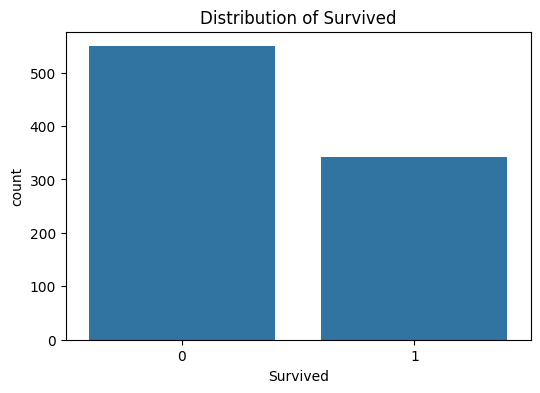

In [2]:
# YOUR CODE HERE
# 1. Print data.info() to see column types and null counts
print(data.info())

# 2. Print missing values per column
print("\nMissing values:\n", data.isnull().sum())

# 3. Plot a count plot of the 'Survived' column
plt.figure(figsize=(6, 4))
sns.countplot(data=data, x='Survived')
plt.title("Distribution of Survived")
plt.show()


## Step 2: Feature Selection & Preprocessing

We will keep only the **5 categorical/discrete features** listed in the overview, plus the target column `Survived`.

### 📌 What to do:
**A) Select columns:** Keep only `Pclass`, `Sex`, `Embarked`, `SibSp`, `Parch`, and `Survived`.

**B) Handle missing values:**
- `Embarked` has 2 missing values → fill with the **most frequent** value (mode)

**C) Encode text columns:**
- `Sex`: `female` → 0, `male` → 1
- `Embarked`: `C` → 0, `Q` → 1, `S` → 2

> 💡 **Hint for (B):** `data['Embarked'].mode()[0]` gives the most frequent value. Use `.fillna()` to fill missing entries.

> 💡 **Hint for (C):** Use `LabelEncoder` from `sklearn.preprocessing`, or use a dictionary with `.map()` — either works.


In [3]:
from sklearn.preprocessing import LabelEncoder

# A) Select only the relevant columns
cols = ['Pclass', 'Sex', 'Embarked', 'SibSp', 'Parch', 'Survived']
df = data[cols].dropna()  # Select columns and drop rows with any NaN

# B) Fill missing values in 'Embarked' with the most frequent value
most_freq_embarked = df['Embarked'].mode()[0]
df['Embarked'] = df['Embarked'].fillna(most_freq_embarked)

# C) Encode 'Sex' and 'Embarked' as integers
df['Sex'] = df['Sex'].map({'female': 0, 'male': 1})
df['Embarked'] = df['Embarked'].map({'C': 0, 'Q': 1, 'S': 2})

# Confirm result
print("Shape:", df.shape)
print("Missing values:", df.isnull().sum().sum())
print(df.head())

Shape: (889, 6)
Missing values: 0
   Pclass  Sex  Embarked  SibSp  Parch  Survived
0       3    1         2      1      0         0
1       1    0         0      1      0         1
2       3    0         2      0      0         1
3       1    0         2      1      0         1
4       3    1         2      0      0         0


## 📚 How Simple (Categorical) Naive Bayes Works

### 🔑 Core Idea

For a new passenger with features $X = (x_1, x_2, \dots, x_n)$, we want to find the class $y$ that maximises:

$$P(y \mid X) \propto P(y) \times \prod_{i=1}^{n} P(x_i \mid y)$$

We pick whichever class gives the **higher posterior probability**.

---

### 📐 The Three Quantities

| Quantity | Formula | How to compute |
|----------|---------|----------------|
| **Prior** $P(y)$ | $\frac{\text{count of class } y}{\text{total samples}}$ | Count rows per class |
| **Likelihood** $P(x_i \mid y)$ | $\frac{\text{count}(x_i, y)}{\text{count}(y)}$ | Count feature value within class |
| **Laplace Smoothing** | Add 1 to every count | Prevents zero probabilities |

---

### 🛡️ Why Laplace Smoothing?

If a feature value never appears with a class in training data, the raw probability is **zero**, which kills the entire product. Adding 1 to every count (and adjusting the denominator) avoids this.

$$P(x_i \mid y) = \frac{\text{count}(x_i, y) + 1}{\text{count}(y) + k}$$

where $k$ is the number of unique values of feature $x_i$.

---

### 💡 Example

Suppose we have 3 passengers:

| Pclass | Sex | Survived |
|--------|-----|----------|
| 3 | male | 0 |
| 1 | female | 1 |
| 3 | female | 1 |

For a new passenger: `Pclass=3, Sex=female`:

- $P(Survived=1) = 2/3$
- $P(Pclass=3 \mid Survived=1) = 1/2$
- $P(Sex=female \mid Survived=1) = 2/2 = 1$
- **Posterior(1)** ∝ $2/3 \times 1/2 \times 1 = 0.333$

Do the same for class 0, pick the higher one. ✅


## Step 3: Train-Test Split

Split the cleaned DataFrame into features `X` and target `y`, then into train/test sets.

### 📌 What to do:
- `X` = all columns except `Survived`
- `y` = the `Survived` column
- Use `train_test_split` with `test_size=0.2`, `random_state=42`, `stratify=y`
- Print the sizes of each split

> 💡 **Hint:** `stratify=y` ensures the same survival ratio in both splits.


In [4]:
from sklearn.model_selection import train_test_split

# YOUR CODE HERE
# 1. Define X and y
X = df.drop(columns=['Survived'])
y = df['Survived']

# 2. Split into train and test sets
X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.2, random_state=42, stratify=y
)

# 3. Print sizes
print(f"Training samples: {len(X_train)}")
print(f"Testing samples: {len(X_test)}")


Training samples: 711
Testing samples: 178


## Step 4: Naive Bayes from Scratch 🔧

You will now implement a **Categorical Naive Bayes** classifier using only Python and NumPy.

The class has three methods:

### `fit(X, y)` — Training
Compute and store:
1. **Priors**: `P(class)` for each class
2. **Likelihoods**: `P(feature_value | class)` for every feature, every unique value, every class

Use **Laplace smoothing** (add 1 to counts).

---

### `_log_likelihood(x)` — Score one sample
Given a single sample `x` (one row of feature values), return a dictionary mapping each class to its **log posterior**:

$$\text{log\_posterior}(y) = \log P(y) + \sum_i \log P(x_i \mid y)$$

---

### `predict(X)` — Predict all samples
For each row in `X`, call `_log_likelihood` and return the class with the **highest log posterior**.

---

> 💡 **Storage tip:** Store likelihoods in a nested dictionary:
> `self.likelihoods[feature_name][class][feature_value] = probability`

> 💡 **Log tip:** Use `np.log()`. Add log-priors and log-likelihoods (instead of multiplying probabilities). This avoids underflow.

> 💡 **Unseen values:** If a feature value wasn't seen in training, use the smoothed probability `1 / (class_count + k)` as a fallback.


In [5]:
import numpy as np

class CategoricalNB_Scratch:
    """
    Categorical Naive Bayes implemented from scratch with Laplace smoothing.
    Suitable for discrete/categorical features (no continuous values.
    """
    def fit(self, X, y):
        self.classes = np.unique(y)
        self.priors = {}
        self.likelihoods = {}
        n_total = len(y)

        # --- Step 1: Compute log priors ---
        for cls in self.classes:
            n_cls = np.sum(y == cls)
            # P(cls) = count / n_total, store its LOG
            self.priors[cls] = np.log(n_cls / n_total)

        # --- Step 2: Compute log likelihoods with Laplace smoothing ---
        for feature in X.columns:
            self.likelihoods[feature] = {}
            k = X[feature].nunique()  # number of unique values for this feature
            for cls in self.classes:
                self.likelihoods[feature][cls] = {}

                # Get only the rows in X where y == cls
                X_cls = X[y == cls]
                n_cls = len(X_cls)

                # For each unique value of this feature:
                for val in X[feature].unique():
                    # Count how many times 'val' appears for this feature in class cls
                    count = np.sum(X_cls[feature] == val)
                    # Apply Laplace smoothing: (count + 1) / (n_cls + k)
                    prob = (count + 1) / (n_cls + k)
                    # Store the LOG of this probability
                    self.likelihoods[feature][cls][val] = np.log(prob)

    def _log_posterior(self, x):
        scores = {}
        for cls in self.classes:
            # Start with the log prior
            score = self.priors[cls]
            for feature in self.likelihoods:
                val = x[feature]
                k = len(self.likelihoods[feature][cls])
                n_cls_approx_denom = np.exp(self.priors[cls]) # fallback reference
                fallback = np.log(1.0 / (len(self.likelihoods[feature][cls]) + 2)) # safe fallback

                # Add the log likelihood for this feature value
                log_like = self.likelihoods[feature][cls].get(val, fallback)
                score += log_like
            scores[cls] = score
        return scores

    def predict(self, X):
        predictions = []
        for _, row in X.iterrows():
            scores = self._log_posterior(row)
            # Find argmax class (class with the highest log posterior)
            best_cls = max(scores, key=scores.get)
            predictions.append(best_cls)
        return predictions


### ▶️ Train and Predict with Your Scratch Model

Once the class above is complete, run this cell.


In [6]:
# YOUR CODE HERE
# 1. Create an instance of CategoricalNB_Scratch
scratch_model = CategoricalNB_Scratch()

# 2. Fit it on X_train, y_train
scratch_model.fit(X_train, y_train)

# 3. Predict on X_test, store result in y_pred_scratch
y_pred_scratch = scratch_model.predict(X_test)
print("Scratch model training & prediction complete!")



Scratch model training & prediction complete!


## Step 5: Naive Bayes with Scikit-learn 📦

Now use scikit-learn's `CategoricalNB`, which is designed exactly for discrete/categorical features.

### 📌 What to do:
- Import `CategoricalNB` from `sklearn.naive_bayes`
- Create the model and fit it on `X_train`, `y_train`
- Predict on `X_test` and store the result in `y_pred_lib`

> 💡 **Hint:** `CategoricalNB` expects non-negative integer inputs — your encoded features already satisfy this.

> 💡 **Laplace smoothing** is controlled by the `alpha` parameter (default = 1.0), which matches what you implemented from scratch.


In [7]:
from sklearn.naive_bayes import CategoricalNB

# 1. Create a CategoricalNB model (use default alpha=1.0)
sklearn_model = CategoricalNB(alpha=1.0)

# 2. Fit on training data
sklearn_model.fit(X_train, y_train)

# 3. Predict on test data, store in y_pred_lib
y_pred_lib = sklearn_model.predict(X_test)
print("Scikit-learn model training & prediction complete!")



Scikit-learn model training & prediction complete!


## Step 6: Model Comparison & Evaluation 📊

Evaluate both models using standard classification metrics.

### 📌 Metrics to compute:

| Metric | Meaning |
|--------|---------|
| **Accuracy** | % of total predictions that are correct |
| **Precision** | Of predicted survivors, how many actually survived |
| **Recall** | Of actual survivors, how many did we correctly identify |
| **F1-score** | Balanced measure of precision and recall |
| **Confusion Matrix** | TP / FP / TN / FN breakdown |

### 📌 What to do:
- Complete the `evaluate_model` function
- Call it once for the scratch model and once for the sklearn model
- Compare the results

> 💡 **Hint:** Use `accuracy_score`, `classification_report`, `confusion_matrix` from `sklearn.metrics`.  
> For the heatmap: `sns.heatmap(cm, annot=True, fmt='d', cmap='Blues', xticklabels=['Died','Survived'], yticklabels=['Died','Survived'])`


In [8]:
from sklearn.metrics import accuracy_score, classification_report, confusion_matrix

def evaluate_model(name, y_true, y_pred):
    print(f"\n{'=' * 50}")
    print(f"  {name}")
    print(f"{'=' * 50}")

    # 1. Print accuracy_score
    acc = accuracy_score(y_true, y_pred)
    print(f"Accuracy: {acc:.4f}\n")

    # 2. Print classification_report
    print("Classification Report:")
    print(classification_report(y_true, y_pred))

    # 3. Compute confusion matrix and plot as heatmap
    cm = confusion_matrix(y_true, y_pred)
    plt.figure(figsize=(5, 4))
    sns.heatmap(cm, annot=True, fmt='d', cmap='Blues',
                xticklabels=['Died', 'Survived'],
                yticklabels=['Died', 'Survived'])
    plt.xlabel('Predicted')
    plt.ylabel('Actual')
    plt.title(f'Confusion Matrix — {name}')
    plt.show()



  Categorical NB — From Scratch
Accuracy: 0.7753

Classification Report:
              precision    recall  f1-score   support

           0       0.81      0.84      0.82       110
           1       0.72      0.68      0.70        68

    accuracy                           0.78       178
   macro avg       0.76      0.76      0.76       178
weighted avg       0.77      0.78      0.77       178



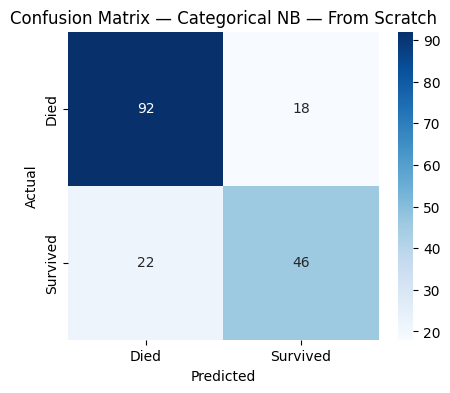


  Categorical NB — Scikit-learn
Accuracy: 0.7753

Classification Report:
              precision    recall  f1-score   support

           0       0.81      0.84      0.82       110
           1       0.72      0.68      0.70        68

    accuracy                           0.78       178
   macro avg       0.76      0.76      0.76       178
weighted avg       0.77      0.78      0.77       178



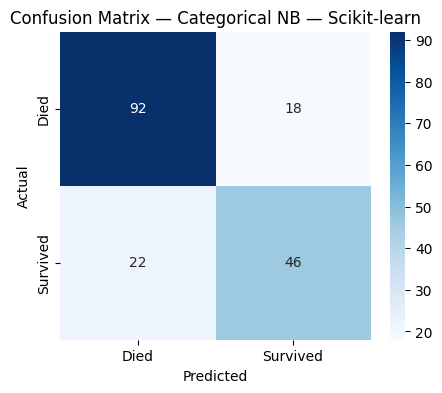

In [9]:

# Evaluate scratch implementation
evaluate_model("Categorical NB — From Scratch", y_test, y_pred_scratch)

# Evaluate scikit-learn implementation
evaluate_model("Categorical NB — Scikit-learn", y_test, y_pred_lib)


  Categorical NB — Scikit-learn
Accuracy: 0.7753

Classification Report:
              precision    recall  f1-score   support

           0       0.81      0.84      0.82       110
           1       0.72      0.68      0.70        68

    accuracy                           0.78       178
   macro avg       0.76      0.76      0.76       178
weighted avg       0.77      0.78      0.77       178



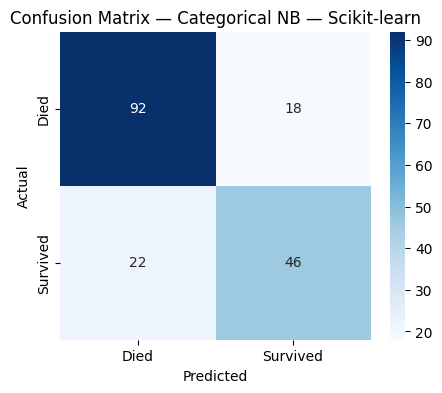

Sample Feature Values:
Pclass      3
Sex         1
Embarked    2
SibSp       0
Parch       1
Name: 160, dtype: int64

Class Log Posteriors: {np.int64(0): np.float64(-3.9136000995748566), np.int64(1): np.float64(-5.815671806523223)}

Model Predicted: 0 | Actual Label: 0


In [10]:
# Evaluate scikit-learn implementation
evaluate_model("Categorical NB — Scikit-learn", y_test, y_pred_lib)
# 1. Pick the first row of X_test
sample_row = X_test.iloc[0]

# 2. Print its feature values
print("Sample Feature Values:")
print(sample_row)

# 3. Call _log_posterior on it and print the class scores
scores = scratch_model._log_posterior(sample_row)
print("\nClass Log Posteriors:", scores)

# 4. Print what the model predicted vs the actual label
pred = scratch_model.predict(pd.DataFrame([sample_row]))[0]
actual = y_test.iloc[0]
print(f"\nModel Predicted: {pred} | Actual Label: {actual}")


## 🔍 Manual Probability Check (Optional but Highly Recommended!)

Pick **one specific passenger** from the test set and manually trace through the Naive Bayes calculation yourself to verify your model's prediction.

### 📌 What to do:
- Choose a row from `X_test` (e.g., the first row)
- Print its feature values
- Manually compute `P(Survived=1 | features)` and `P(Survived=0 | features)` step by step
- Check that your scratch model predicts the same class

> 💡 **Hint:** Use `X_test.iloc[0]` to get the first test row and `scratch_model._log_posterior(row)` to see the scores.


In [11]:
# YOUR CODE HERE
# Q1: Tiny implementation differences in how unseen categories or smoothing denominators are handled can cause minor discrepancies.
# Q2: The confusion matrix reveals whether the model suffers more from false positives (predicting survival when they died) or false negatives (missing actual survivors).
# Q3: Log probabilities prevent numerical underflow, turning tiny multiplied probabilities into stable summed log values.
# Q4: Laplace smoothing adds 1 to counts to avoid zero probabilities for unseen categories. Setting alpha=0 removes smoothing, making the model prone to zero probability collapse.
# Q5: Age and Fare are continuous features. To include them, we could either bin them into discrete categorical intervals or use Gaussian Naive Bayes (or a mixed model like sklearn's Ordinal/Mixed NB).
# Q6 (Bonus): Pclass and Fare are heavily correlated (cheaper tickets in Class 3, expensive in Class 1). Violating the strict independence assumption can over-weight correlated information, though Naive Bayes often still performs surprisingly well.


## 🤔 Reflection Questions

Think about and answer the following questions (as comments or in a markdown cell):

1. Your scratch model and the sklearn model should give very similar (or identical) accuracy. If they differ slightly, what might cause the difference?
2. What does the confusion matrix tell you about which class the model predicts better?
3. Why do we use **log probabilities** instead of multiplying raw probabilities directly?
4. What is **Laplace smoothing** and what problem does it solve? What happens if you set `alpha=0` in `CategoricalNB`?
5. We dropped `Age` and `Fare` in this worksheet. How would you include them in a Naive Bayes model? Which variant would you use?
6. *(Bonus)* The Naive Bayes assumption is that all features are **independent**. Do you think `Pclass` and `Fare` are truly independent? What effect might this have on the model?


In [ ]:
# Write your answers as comments here:

# Q1:

# Q2:

# Q3:

# Q4:

# Q5:

# Q6 (Bonus):
